# Securitised Auto-Loan Pool: Early-Warning Indicators

Investors in an auto-loan securitisation watch the pool every month, but the headline numbers arrive late: a borrower shows up as 60 days late two months after the first missed payment, and losses come months after that. Earlier signals sit in the monthly flows, once the pool's normal ageing and seasonal pattern are taken out. This notebook builds that early-warning system from a real deal's loan-level filings.

**What it does.** It turns the loan-level filings of a public auto-loan securitisation (CarMax Auto Owner Trust 2022-4, about 67,700 loans and $1.66bn at closing) into a monthly early-warning system.

In SQL it builds the indicators a surveillance analyst tracks: delinquency buckets, roll rates, cure rates, net losses, payment ratios, prepayment and modifications. It removes the pool's expected seasonality and seasoning, and detects structural breaks with change-point methods and a one-sided CUSUM run month by month.

An Isolation Forest flags anomalous loans and is tested on whether loans that are still current go on to default. Control charts by borrower segment and a RAG dashboard complete it.

**Data.** SEC EDGAR Form ABS-EE, Exhibit 102 (Regulation AB II asset-level data) for CarMax Auto Owner Trust 2022-4: every monthly filing from closing (October 2022) to the latest report, about 2 million loan-months.

**Methods.** DuckDB SQL over the monthly tapes, a log-linear expected path with month-of-year and loan-age terms, PELT change-point detection (ruptures) and a one-sided CUSUM with an expanding-window baseline.

The Isolation Forest (unsupervised) is scored out of time by AUC against realised defaults, and binomial control charts cover each segment.

**Key output.** The indicator history with detected breaks and CUSUM alarms, how far ahead the alarms come compared with the 60+ delinquency rate, the anomaly score's power to anticipate defaults among loans that are still current, segment flags, and an interactive dashboard.

## 1. Why surveillance needs more than the delinquency rate

An ABS investor or a bank funding the issuer watches the pool every month. The headline numbers (60+ day delinquency, cumulative net loss) arrive late:
- a borrower is 60 days late two months after the first missed payment;
- a charge-off follows a repossession and auction months later.

Earlier signals sit in the flows:
- **roll rates:** the share of current loans that become 30 days late, and of 30-day loans that roll to 60;
- **cure rates;**
- **payment ratios:** cash received ÷ cash due;
- **partial payments, extensions and modifications.**

Two complications make raw time series misleading for a single static pool:

- **Seasoning.** Losses on an auto pool peak 12–24 months after origination, and ratios over a shrinking balance mechanically rise as good borrowers prepay.
- **Seasonality.** U.S. auto delinquencies rise in Q4 and fall in February–April, when tax refunds arrive.

So the useful question is not "is delinquency up?" but **"is it up more than this pool's age and the calendar would predict?"**

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import duckdb
import ruptures as rpt
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 3
# Isolation Forest is fitted on the first year of reporting and scored
# afterwards
ANOMALY_TRAIN_MONTHS = 12
OUTCOME_WINDOW = (
    6  # months ahead for "becomes 60+ days late or is charged off"
)
# CUSUM allowance and decision threshold (in residual standard deviations)
CUSUM_K, CUSUM_H = 0.5, 4.0

print(
    f"duckdb {duckdb.__version__} · ruptures {rpt.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

duckdb 1.5.6 · ruptures v1.1.10 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


# --- SEC EDGAR ABS-EE loader
import os, time, json, requests
from lxml import etree

ABS_CIK = 1946521  # CarMax Auto Owner Trust 2022-4


def repo_root():
    """
    The folder that holds .git (falls back to the parent of this project's
    folder).
    """
    return next(
        (
            d
            for d in [PROJECT_DIR, *PROJECT_DIR.parents]
            if (d / ".git").exists()
        ),
        PROJECT_DIR.parent,
    )


# Shared download cache, at the repo root (or wherever it already exists above
# this project); never committed
ABS_DIR = next(
    (
        d / "data" / "absee_cart20224"
        for d in [PROJECT_DIR, *PROJECT_DIR.parents]
        if (d / "data" / "absee_cart20224").exists()
    ),
    repo_root() / "data" / "absee_cart20224",
)
ABS_DIR.mkdir(parents=True, exist_ok=True)
NS = "{http://www.sec.gov/edgar/document/absee/autoloan/assetdata}"
KEEP = {
    "assetNumber": "loan_id",
    "reportingPeriodEndingDate": "period_end",
    "originationDate": "orig_date",
    "originalLoanAmount": "orig_amt",
    "originalLoanTerm": "orig_term",
    "originalInterestRatePercentage": "orig_rate",
    "vehicleNewUsedCode": "new_used",
    "vehicleModelYear": "model_year",
    "vehicleValueAmount": "vehicle_value",
    "obligorCreditScore": "fico",
    "paymentToIncomePercentage": "pti",
    "obligorGeographicLocation": "state",
    "coObligorIndicator": "co_obligor",
    "remainingTermToMaturityNumber": "rem_term",
    "reportingPeriodBeginningLoanBalanceAmount": "beg_bal",
    "reportingPeriodActualEndBalanceAmount": "end_bal",
    "reportingPeriodScheduledPaymentAmount": "sched_pmt",
    "totalActualAmountPaid": "paid",
    "currentDelinquencyStatus": "dq_days",
    "zeroBalanceCode": "zb_code",
    "zeroBalanceEffectiveDate": "zb_date",
    "chargedoffPrincipalAmount": "chargeoff",
    "recoveredAmount": "recovered",
    "repossessedIndicator": "repossessed",
    "reportingPeriodModificationIndicator": "modified",
    "vehicleManufacturerName": "make",
}
NUM = [
    "orig_amt",
    "orig_term",
    "orig_rate",
    "model_year",
    "vehicle_value",
    "fico",
    "pti",
    "rem_term",
    "beg_bal",
    "end_bal",
    "sched_pmt",
    "paid",
    "dq_days",
    "chargeoff",
    "recovered",
]


SEC = requests.Session()


def sec_get(url, **kw):
    """
    GET from EDGAR with the declared User-Agent, retrying on timeouts and
    throttling.
    """
    for attempt in range(6):
        try:
            r = SEC.get(
                url,
                headers={"User-Agent": os.environ["SEC_USER_AGENT"]},
                timeout=(20, 180),
                **kw,
            )
            if r.status_code == 200:
                return r
        except requests.RequestException:
            pass
        time.sleep(3 + 5 * attempt)
    raise RuntimeError(f"EDGAR request failed: {url}")


def absee_filings():
    cache = ABS_DIR / "filings.json"
    if cache.exists() and time.time() - cache.stat().st_mtime < 20 * 86400:
        return [tuple(x) for x in json.loads(cache.read_text())]
    j = sec_get(
        f"https://data.sec.gov/submissions/CIK{ABS_CIK:010d}.json"
    ).json()["filings"]["recent"]
    out = []
    for i, form in enumerate(j["form"]):
        if form != "ABS-EE":
            continue
        acc = j["accessionNumber"][i].replace("-", "")
        idx = sec_get(
            f"https://www.sec.gov/Archives/edgar/data/{ABS_CIK}/{acc}/index.json"
        ).json()["directory"]["item"]
        xml = [
            it["name"]
            for it in idx
            if it["name"].endswith(".xml")
            and not it["name"].startswith("exhibit103")
        ]
        if xml:
            out.append((
                j["filingDate"][i],
                f"https://www.sec.gov/Archives/edgar/data/{ABS_CIK}/{acc}/{xml[0]}",
            ))
        time.sleep(0.15)
    cache.write_text(json.dumps(sorted(out)))
    return sorted(out)


def parse_absee(url, dest):
    """
    Stream one EX-102 asset-data file and keep the loans still alive at the
    start of the period (or closing in it).
    """
    rows = []
    with sec_get(url, stream=True) as r:
        r.raw.decode_content = True
        for _, el in etree.iterparse(
            r.raw, events=("end",), tag=NS + "assets"
        ):
            rec = {}
            for ch in el:
                k = KEEP.get(ch.tag.replace(NS, ""))
                if k:
                    rec[k] = ch.text
            el.clear()
            while el.getprevious() is not None:
                del el.getparent()[0]
            beg, recov = float(rec.get("beg_bal") or 0), float(
                rec.get("recovered") or 0
            )
            # live loans, plus later recoveries on charged-off loans
            if beg > 0 or rec.get("zb_code") is None or recov != 0:
                rows.append(rec)
    df = pd.DataFrame(rows)
    for c in NUM:
        if c in df:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df.to_parquet(dest, index=False)
    return len(df)


def sync_absee():
    """
    Download and compact every monthly asset-data file not yet cached (about 7
    seconds each).
    """
    for fdate, url in absee_filings():
        name = url.rsplit("/", 1)[-1]
        dest = ABS_DIR / f"{fdate}_{name.replace('.xml', '')}.parquet"
        if not dest.exists():
            t0 = time.time()
            n = parse_absee(url, dest)
            print(f"  {fdate} {name}: {n:,} loans in {time.time() - t0:.0f}s")

## 3. Data: the ABS-EE asset-level tapes

Since 2016, Regulation AB II has required issuers of public auto-loan ABS to file every loan's data each month on Form ABS-EE: origination terms (amount, rate, term, credit score, payment-to-income, vehicle value), and that month's balance, scheduled and actual payment, days delinquent, modification, repossession, charge-off and recovery. The loader streams each 100–200 MB XML file and keeps 26 fields for:
- loans alive at the start of the month;
- loans that closed during it;
- later recoveries on charged-off loans.

Each file is compacted to Parquet. The two pre-closing pool tapes are excluded. Downloads go through the SEC's fair-access policy with the User-Agent declared in `.env`.

In [3]:
sync_absee()
con = duckdb.connect()
con.execute("SET enable_progress_bar = false")
con.execute(f"""
CREATE OR REPLACE VIEW tape AS
SELECT *, CAST(strptime(period_end, '%m-%d-%Y') AS DATE) AS period,
       COALESCE(chargeoff, 0) AS co_amt, COALESCE(recovered, 0) AS rec_amt
FROM read_parquet('{(ABS_DIR / "2*.parquet").as_posix()}', union_by_name = true, filename = true)
WHERE filename NOT LIKE '%b.parquet' AND filename NOT LIKE '%u.parquet'""")
info = con.execute(
    """SELECT COUNT(*) AS loan_months, COUNT(DISTINCT loan_id) AS loans, MIN(period) AS first, MAX(period) AS last,
                             COUNT(DISTINCT period) AS months FROM tape"""
).df()
orig = (
    con.execute(
        """SELECT SUM(orig_amt) AS amt, AVG(fico) AS fico, AVG(pti) AS pti, AVG(orig_rate) AS rate, AVG(orig_term) AS term,
                             AVG(CASE WHEN new_used = '1' THEN 1.0 ELSE 0 END) AS new_share
                      FROM (SELECT DISTINCT ON (loan_id) * FROM tape ORDER BY loan_id, period)"""
    )
    .df()
    .iloc[0]
)
cut = con.execute(
    "SELECT SUM(beg_bal) FROM tape WHERE period = (SELECT MIN(period) FROM"
    " tape)"
).fetchone()[0]
print(
    f"{info['loan_months'][0]:,} loan-months · {info['loans'][0]:,} loans ·"
    f" {info['first'][0]:%Y-%m} to"
    f" {info['last'][0]:%Y-%m} ({info['months'][0]} months)"
)
print(
    f"At origination: ${orig['amt'] / 1e6:,.0f}mm, mean FICO"
    f" {orig['fico']:.0f}, mean PTI {orig['pti']:.1%}, mean APR"
    f" {orig['rate']:.2%}, mean term {orig['term']:.0f} months,"
    f" {orig['new_share']:.1%} new vehicles · pool balance at the first report"
    f" ${cut / 1e6:,.0f}mm"
)

2,031,692 loan-months · 67,666 loans · 2022-10 to 2026-09 (48 months)
At origination: $1,657mm, mean FICO 714, mean PTI 8.4%, mean APR 8.55%, mean term 66 months, 0.0% new vehicles · pool balance at the first report $1,430mm


## 4. Pool indicators in SQL

One query builds the monthly indicator panel. Delinquency is measured by balance at month end, over loans with a positive balance. Roll and cure rates use each loan's status in the previous month (`LAG`).

| Indicator | Definition |
|---|---|
| 30+ / 60+ / 90+ DQ % | balance 30/60/90+ days past due ÷ pool balance |
| roll C→30 % | loans current last month that are 30+ days late now |
| roll 30→60 % | loans 30–59 days late last month that are 60+ days late now |
| cure 30+ → C % | loans 30+ days late last month that are current now |
| net loss rate % (ann.) | (charge-offs − recoveries) × 12 ÷ start-of-month balance |
| CNL % | cumulative net losses ÷ pool balance at the first report (the market convention: % of initial pool balance) |
| pool factor % | pool balance ÷ pool balance at the first report |
| CPR % | voluntary payoffs (zero-balance code 1) as an annualised share of balance |
| payment ratio % | cash paid ÷ scheduled payment, loans active at the start of the month |
| partial-pay % | loans that paid something but less than half the scheduled amount |
| modified % | loans flagged as modified (including extensions) in the month |

In [4]:
ind = con.execute(f"""
WITH t AS (
  SELECT loan_id, period, orig_date, beg_bal, end_bal, sched_pmt, paid, COALESCE(dq_days, 0) AS dq, zb_code, co_amt, rec_amt, modified, repossessed,
         LAG(COALESCE(dq_days, 0)) OVER (PARTITION BY loan_id ORDER BY period) AS dq_prev
  FROM tape)
SELECT period,
  COUNT(*) FILTER (WHERE beg_bal > 0) AS loans,
  SUM(beg_bal) AS beg_bal, SUM(CASE WHEN end_bal > 0 THEN end_bal END) AS end_bal,
  100 * SUM(CASE WHEN end_bal > 0 AND dq >= 30 THEN end_bal END) / SUM(CASE WHEN end_bal > 0 THEN end_bal END) AS dq30,
  100 * SUM(CASE WHEN end_bal > 0 AND dq >= 60 THEN end_bal END) / SUM(CASE WHEN end_bal > 0 THEN end_bal END) AS dq60,
  100 * SUM(CASE WHEN end_bal > 0 AND dq >= 90 THEN end_bal END) / SUM(CASE WHEN end_bal > 0 THEN end_bal END) AS dq90,
  100 * AVG(CASE WHEN dq_prev < 30 AND beg_bal > 0 THEN (dq >= 30)::INT END) AS roll_c30,
  100 * AVG(CASE WHEN dq_prev >= 30 AND dq_prev < 60 AND beg_bal > 0 THEN (dq >= 60 OR co_amt > 0)::INT END) AS roll_3060,
  100 * AVG(CASE WHEN dq_prev >= 30 AND beg_bal > 0 THEN (dq < 30 AND co_amt = 0)::INT END) AS cure,
  SUM(co_amt) AS chargeoffs, SUM(rec_amt) AS recoveries,
  100 * 12 * (SUM(co_amt) - SUM(rec_amt)) / SUM(beg_bal) AS nlr,
  100 * (1 - POWER(1 - SUM(CASE WHEN zb_code = '1' THEN beg_bal END) / SUM(beg_bal), 12)) AS cpr,
  100 * SUM(CASE WHEN beg_bal > 0 AND zb_code IS NULL THEN paid END) / SUM(CASE WHEN beg_bal > 0 AND zb_code IS NULL THEN sched_pmt END) AS pay_ratio,
  100 * AVG(CASE WHEN beg_bal > 0 AND zb_code IS NULL AND sched_pmt > 0 THEN (paid > 0 AND paid < 0.5 * sched_pmt)::INT END) AS partial,
  100 * AVG(CASE WHEN beg_bal > 0 THEN (modified = 'true')::INT END) AS modified,
  COUNT(*) FILTER (WHERE repossessed = 'true') AS repos,
  AVG(CASE WHEN beg_bal > 0 THEN date_diff('month', CAST(strptime(orig_date, '%m/%Y') AS DATE), period) END) AS age
FROM t GROUP BY period ORDER BY period""").df().set_index("period")
ind.index = pd.to_datetime(ind.index)
# % of the pool balance at the first report
ind["cnl"] = 100 * (ind["chargeoffs"] - ind["recoveries"]).cumsum() / cut
ind["pool factor %"] = 100 * ind["end_bal"] / cut
# no prior month inside the tapes
ind.loc[ind.index[0], ["roll_c30", "roll_3060", "cure"]] = np.nan
show = [
    "loans",
    "pool factor %",
    "dq30",
    "dq60",
    "roll_c30",
    "roll_3060",
    "cure",
    "nlr",
    "cnl",
    "cpr",
    "pay_ratio",
    "partial",
    "modified",
]
ind[show].iloc[::6].round(2)

,loans,pool factor %,dq30,dq60,roll_c30,roll_3060,cure,nlr,cnl,cpr,pay_ratio,partial,modified
period,,,,,,,,,,,,,
2022-10-31,67666,97.03,0.86,0.04,NaN,NaN,NaN,0.00,0.00,14.93,106.16,0.70,0.20
2023-04-30,59750,80.69,3.06,1.21,0.95,32.72,24.19,1.34,0.43,12.17,106.08,0.78,0.57
2023-10-31,51608,66.12,5.08,2.22,1.30,32.21,19.89,2.48,1.32,12.03,105.65,1.02,0.89
2024-04-30,45050,54.01,5.04,2.34,1.16,31.20,23.54,3.06,2.29,13.11,100.73,1.56,1.09
2024-10-31,39345,43.15,5.17,1.88,1.56,24.62,31.73,4.15,3.18,13.93,102.82,1.58,1.60
2025-04-30,35206,33.64,6.33,2.71,1.46,33.46,23.74,3.55,3.93,14.16,101.72,1.57,1.06
2025-10-31,30848,24.89,7.73,3.13,1.54,25.98,22.08,5.86,4.65,17.02,101.09,1.40,1.32
2026-04-30,26811,17.45,8.05,3.62,1.48,29.63,23.07,3.58,5.19,20.88,100.84,1.26,0.90


## 5. Expected path, change points and CUSUM alarms

For each indicator $y_t$, an **expected path** is fitted on $\log y_t$:
- month-of-year dummies (seasonality);
- $\log(\text{age})$ and age (seasoning).

The residuals are what the pool is doing beyond what its calendar and age imply. Two detectors run on them:

1. **PELT change points in the trend.** These are retrospective. Month-of-year effects are removed, and a continuous piecewise-linear path is fitted to the log indicator (ruptures' `clinear` cost), with a BIC-style penalty scaled by the month-to-month noise. A change point is a month where the indicator's growth rate changes.
2. **One-sided CUSUM, run in real time.** At each month $t$ the expected path is re-fitted on data up to $t-1$ only, and the standardised forecast error $e_t$ feeds $S_t=\max(0,S_{t-1}+e_t-k)$, with an alarm when $S_t>h$ ($k=0.5$, $h=4$). This is the surveillance analyst's view: an alarm uses only information available at the time.

Five indicators are monitored from January 2023, the fourth report, when charge-offs begin. Real-time fitting needs 15 months of history, so the CUSUM starts in April 2024.

A caveat: for a single static pool, loan age and calendar time move together. The expected path cannot separate "seasoning as usual" from "the economy got worse", and the full-sample fit absorbs much of any gradual deterioration. The real-time CUSUM is the fairer test, because it compares each month with the curve extrapolated from earlier months only.

In [5]:
MON = {
    "roll_c30": "Roll current→30 %",
    "roll_3060": "Roll 30→60 %",
    "dq60": "60+ DQ %",
    "nlr": "Net loss rate % (ann.)",
    "partial": "Partial payers %",
}


def design(idx, age):
    m = (
        pd.get_dummies(idx.month, prefix="m", drop_first=True)
        .astype(float)
        .to_numpy()
    )
    return np.column_stack([np.ones(len(idx)), np.log(age), age / 12, m])


def fit_predict(y, idx, age, train):
    X_ = design(idx, age)
    b, *_ = np.linalg.lstsq(X_[train], y[train], rcond=None)
    res = y[train] - X_[train] @ b
    dof = max(train.sum() - X_.shape[1], 3)
    return X_ @ b, np.sqrt((res**2).sum() / dof)


cps, cusum, expected, trend = {}, {}, {}, {}
BURN = 15
# charge-offs only start in the fourth report
START = ind.index[3]
for col, label in MON.items():
    s = ind.loc[START:, col].dropna()
    y = np.log(np.clip(s.to_numpy(), 1e-4, None))
    age = ind.loc[s.index, "age"].to_numpy()
    pred, sig = fit_predict(y, s.index, age, np.ones(len(y), bool))
    expected[col] = pd.Series(np.exp(pred), s.index)
    # Change points in the trend: remove month-of-year effects, then fit a
    # continuous piecewise-linear path (PELT, "clinear" cost)
    m_ = (
        pd.get_dummies(s.index.month, drop_first=True).astype(float).to_numpy()
    )
    Xs = np.column_stack([np.ones(len(y)), np.arange(len(y)) / 12, m_])
    bs, *_ = np.linalg.lstsq(Xs, y, rcond=None)
    ds = y - m_ @ bs[2:]
    noise = np.var(np.diff(ds))
    bk = (
        rpt.Pelt(model="clinear", min_size=6, jump=1)
        .fit(ds.reshape(-1, 1))
        .predict(pen=2 * np.log(len(ds)) * noise)
    )
    cps[col] = [s.index[b] for b in bk[:-1]]
    trend[col] = pd.Series(np.exp(ds), s.index)
    S, alarms, e_all = 0.0, [], []
    for t in range(BURN, len(y)):
        tr = np.zeros(len(y), bool)
        tr[:t] = True
        p_, sg = fit_predict(y, s.index, age, tr)
        e = (y[t] - p_[t]) / sg
        S = max(0.0, S + e - CUSUM_K)
        e_all.append((s.index[t], e, S))
        if S > CUSUM_H:
            alarms.append(s.index[t])
            S = 0.0  # reset after an alarm
    cusum[col] = (
        pd.DataFrame(e_all, columns=["period", "error", "S"]).set_index(
            "period"
        ),
        alarms,
    )

cp_tab = pd.DataFrame({
    MON[c]: {
        "change points (PELT)": (
            ", ".join(f"{d:%Y-%m}" for d in cps[c]) or "none"
        ),
        "CUSUM alarms (real time)": (
            ", ".join(f"{d:%Y-%m}" for d in cusum[c][1]) or "none"
        ),
        "first alarm": (
            min(cusum[c][1]).strftime("%Y-%m") if cusum[c][1] else "—"
        ),
        "latest residual (s.d.)": cusum[c][0]["error"].iloc[-1],
    }
    for c in MON
}).T
cp_tab

,change points (PELT),CUSUM alarms (real time),first alarm,latest residual (s.d.)
Roll current→30 %,"2025-03, 2025-09","2024-12, 2026-08",2024-12,1.75
Roll 30→60 %,2025-06,2024-12,2024-12,0.56
60+ DQ %,"2023-08, 2024-03, 2024-11, 2025-05","2024-08, 2024-12, 2025-01, 2025-03, 2025-05, 2...",2024-08,0.78
Net loss rate % (ann.),"2023-12, 2026-03","2024-10, 2025-03, 2025-08",2024-10,-1.76
Partial payers %,"2023-09, 2024-03, 2025-07","2024-08, 2025-08, 2025-11, 2026-07",2024-08,1.61


### Lead time

If the flow indicators work as early warnings, their alarms should come **before** the 60+ delinquency and net-loss alarms. The cross-correlation of the real-time standardised errors measures the lag at which each flow indicator best anticipates the 60+ residual.

In [6]:
err = pd.DataFrame({c: cusum[c][0]["error"] for c in MON})
lead = {}
for c in ["roll_c30", "roll_3060", "partial"]:
    cc = {L: err[c].shift(L).corr(err["dq60"]) for L in range(0, 7)}
    best = max(cc, key=lambda L: cc[L])
    lead[MON[c]] = {
        "corr at lag 0": cc[0],
        "best lag (months)": best,
        "corr at best lag": cc[best],
    }
lead_tab = pd.DataFrame(lead).T
lead_tab.round(2)

,corr at lag 0,best lag (months),corr at best lag
Roll current→30 %,0.52,1.00,0.60
Roll 30→60 %,0.62,0.00,0.62
Partial payers %,-0.11,6.00,0.09


## 6. Loan-level anomalies among loans that are still current

An early-warning signal is valuable only if it fires **before** delinquency shows. So the anomaly detector is evaluated on loans that are **current** (under 30 days) in month $t$: does its score anticipate the loan becoming 60+ days late or being charged off within the next six months?

Features, all observable in month $t$:
- **this month's behaviour:** payment ratio (paid ÷ scheduled, capped at 3), days past due (0–29), whether a payment was skipped, and modification;
- **the last three months:** the minimum payment ratio and the number of months with any delinquency;
- **origination:** credit score, payment-to-income and loan-to-value at origination;
- **current LTV:** balance ÷ the original vehicle value.

The Isolation Forest is unsupervised: it never sees an outcome. It is fitted on a 200,000-row sample of the first 12 months and scored on everything afterwards. Two benchmarks:
- origination credit score alone;
- a logistic regression on the same features, which uses the labels (on the first 12 months) and so is an upper reference.

In [7]:
panel = con.execute(f"""
WITH t AS (
  SELECT loan_id, period, beg_bal, end_bal, COALESCE(dq_days, 0) AS dq, fico, pti, orig_amt, vehicle_value, co_amt, modified,
         LEAST(CASE WHEN sched_pmt > 0 THEN paid / sched_pmt END, 3) AS pr
  FROM tape WHERE beg_bal > 0),
f AS (
  SELECT *, MIN(pr) OVER w3 AS pr_min3, SUM((dq >= 1)::INT) OVER w3 AS dq_months3,
         MAX(CASE WHEN dq >= 60 OR co_amt > 0 THEN 1 ELSE 0 END) OVER (PARTITION BY loan_id ORDER BY period
             ROWS BETWEEN 1 FOLLOWING AND {OUTCOME_WINDOW} FOLLOWING) AS bad_next,
         COUNT(*) OVER (PARTITION BY loan_id ORDER BY period ROWS BETWEEN 1 FOLLOWING AND {OUTCOME_WINDOW} FOLLOWING) AS n_next
  FROM t WINDOW w3 AS (PARTITION BY loan_id ORDER BY period ROWS BETWEEN 2 PRECEDING AND CURRENT ROW))
SELECT loan_id, period, pr, dq, (pr < 0.05)::INT AS skipped, (modified = 'true')::INT AS modified, pr_min3, dq_months3,
       fico, pti, orig_amt / NULLIF(vehicle_value, 0) AS ltv0, end_bal / NULLIF(vehicle_value, 0) AS cltv,
       COALESCE(bad_next, 0) AS bad_next, n_next
FROM f WHERE dq < 30 AND co_amt = 0 ORDER BY period, loan_id""").df()
panel["period"] = pd.to_datetime(panel["period"])
FEATS = [
    "pr",
    "dq",
    "skipped",
    "modified",
    "pr_min3",
    "dq_months3",
    "fico",
    "pti",
    "ltv0",
    "cltv",
]
panel[FEATS] = (
    panel[FEATS].astype(float).fillna(panel[FEATS].astype(float).median())
)
months = np.sort(panel["period"].unique())
train_end = months[ANOMALY_TRAIN_MONTHS - 1]
# later months do not have a full outcome window yet
last_eval = months[-OUTCOME_WINDOW - 1]
tr = panel[panel["period"] <= train_end]
te = panel[(panel["period"] > train_end) & (panel["period"] <= last_eval)]
iso = IsolationForest(
    n_estimators=300, max_samples=4096, random_state=SEED, n_jobs=-1
).fit(tr[FEATS].sample(200_000, random_state=SEED))
te = te.assign(anomaly=-iso.score_samples(te[FEATS]))
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

sc_ = StandardScaler().fit(tr[FEATS])
lr = LogisticRegression(max_iter=2000, C=1.0).fit(
    sc_.transform(tr[FEATS]), tr["bad_next"]
)
te["logit_p"] = lr.predict_proba(sc_.transform(te[FEATS]))[:, 1]
auc = {
    "Isolation Forest score (unsupervised)": roc_auc_score(
        te["bad_next"], te["anomaly"]
    ),
    "Credit score at origination (lower = riskier)": roc_auc_score(
        te["bad_next"], -te["fico"]
    ),
    "Logistic regression, same features (supervised)": roc_auc_score(
        te["bad_next"], te["logit_p"]
    ),
}
q = te["anomaly"].quantile(0.99)
top = te[te["anomaly"] >= q]
print(
    f"Current loan-months: {len(tr):,} for fitting (to"
    f" {pd.Timestamp(train_end):%Y-%m}), {len(te):,} scored"
    f" ({pd.Timestamp(months[ANOMALY_TRAIN_MONTHS]):%Y-%m} –"
    f" {pd.Timestamp(last_eval):%Y-%m}); {te['bad_next'].mean():.2%} go 60+ or"
    f" charge off within {OUTCOME_WINDOW} months"
)
print(
    f"Top 1% most anomalous: {top['bad_next'].mean():.1%} go bad"
    f" ({top['bad_next'].mean() / te['bad_next'].mean():.0f}× the base rate)"
    " and they account for"
    f" {top['bad_next'].sum() / te['bad_next'].sum():.0%} of all bad outcomes"
)
pd.Series(auc, name="out-of-time AUC").round(3).to_frame()

Current loan-months: 706,497 for fitting (to 2023-09), 1,093,187 scored (2023-10 – 2026-03); 2.10% go 60+ or charge off within 6 months
Top 1% most anomalous: 24.1% go bad (11× the base rate) and they account for 11% of all bad outcomes


,out-of-time AUC
Isolation Forest score (unsupervised),0.84
Credit score at origination (lower = riskier),0.80
"Logistic regression, same features (supervised)",0.90


In [8]:
# Lift by anomaly-score decile and the features that separate the top 1%
te["decile"] = pd.qcut(
    te["anomaly"].rank(method="first"), 10, labels=range(1, 11)
)
lift = (
    te.groupby("decile", observed=True)["bad_next"]
    .agg(["mean", "sum"])
    .rename(columns={"mean": "bad rate", "sum": "bad loans"})
)
lift["share of bad %"] = 100 * lift["bad loans"] / lift["bad loans"].sum()
lift["bad rate"] *= 100
profile = pd.DataFrame({
    "top 1% anomalous": top[FEATS].mean(),
    "all current loans": te[FEATS].mean(),
})
display(lift.round(2).T)
profile.round(3)

decile,1,2,3,4,5,6,7,8,9,10
bad rate,0.42,0.40,0.40,0.40,0.43,0.43,0.71,1.61,4.38,11.84
bad loans,459.00,442.00,434.00,442.00,465.00,468.00,780.00,"1,765.00","4,787.00","12,942.00"
share of bad %,2.00,1.92,1.89,1.92,2.02,2.04,3.39,7.68,20.83,56.31


,top 1% anomalous,all current loans
pr,0.84,1.05
dq,8.29,1.10
skipped,0.46,0.07
modified,0.68,0.01
pr_min3,0.29,0.81
dq_months3,1.85,0.32
fico,643.34,720.81
pti,0.12,0.08
ltv0,0.97,0.90
cltv,0.55,0.53


## 7. Segment control charts

For each segment (credit-score band, payment-to-income band, top states, vehicle age), the latest month's 60+ delinquency rate (by count) is compared with the segment's own mean over the previous 12 months. A binomial z-score flags segments that have deteriorated beyond sampling noise ($|z|>2$ amber, $>3$ red). Unlike the pool-level CUSUM, this uses no seasonal adjustment, so it is a short-horizon screen.

In [9]:
seg = con.execute(
    """
WITH t AS (SELECT period, COALESCE(dq_days, 0) AS dq, fico, pti, state, model_year, EXTRACT(year FROM period) AS yr
           FROM tape WHERE end_bal > 0),
s AS (
  SELECT period, 'FICO ' || CASE WHEN fico < 620 THEN '<620' WHEN fico < 680 THEN '620–679' WHEN fico < 740 THEN '680–739' ELSE '740+' END AS segment, dq FROM t
  UNION ALL SELECT period, 'PTI ' || CASE WHEN pti < 0.08 THEN '<8%' WHEN pti < 0.12 THEN '8–12%' ELSE '12%+' END, dq FROM t
  UNION ALL SELECT period, 'Vehicle age at origination ' || CASE WHEN 2022 - model_year <= 2 THEN '0–2y' WHEN 2022 - model_year <= 5 THEN '3–5y' ELSE '6y+' END, dq FROM t
  UNION ALL SELECT period, 'State ' || state, dq FROM t WHERE state IN ('CA', 'TX', 'FL', 'GA', 'NC', 'VA', 'IL', 'NY'))
SELECT segment, period, COUNT(*) AS n, AVG((dq >= 60)::INT) AS p FROM s GROUP BY 1, 2 ORDER BY 1, 2"""
).df()
seg["period"] = pd.to_datetime(seg["period"])
last = seg["period"].max()
rows = []
for name, g in seg.groupby("segment"):
    g = g.set_index("period").sort_index()
    base = g.loc[g.index < last].iloc[-12:]
    p0, n1, p1 = base["p"].mean(), g.loc[last, "n"], g.loc[last, "p"]
    z = (p1 - p0) / np.sqrt(max(p0 * (1 - p0), 1e-9) / n1)
    rows.append({
        "segment": name,
        "loans": int(n1),
        "60+ % latest": p1 * 100,
        "60+ % prior 12m": p0 * 100,
        "z": z,
        "flag": "red" if z > 3 else "amber" if z > 2 else "green",
    })
seg_tab = (
    pd.DataFrame(rows).set_index("segment").sort_values("z", ascending=False)
)
seg_tab.round(2)

,loans,60+ % latest,60+ % prior 12m,z,flag
segment,,,,,
Vehicle age at origination 6y+,6318,3.12,2.60,2.61,amber
PTI <8%,12578,1.61,1.34,2.56,amber
FICO 680–739,5662,1.66,1.36,1.96,green
FICO 620–679,5106,4.15,3.67,1.85,green
State FL,1705,3.81,3.05,1.84,green
Vehicle age at origination 0–2y,4444,2.50,2.16,1.56,green
PTI 8–12%,4828,3.31,2.95,1.51,green
State NC,1141,3.07,2.39,1.50,green
Vehicle age at origination 3–5y,11528,2.40,2.20,1.47,green


## 8. Charts

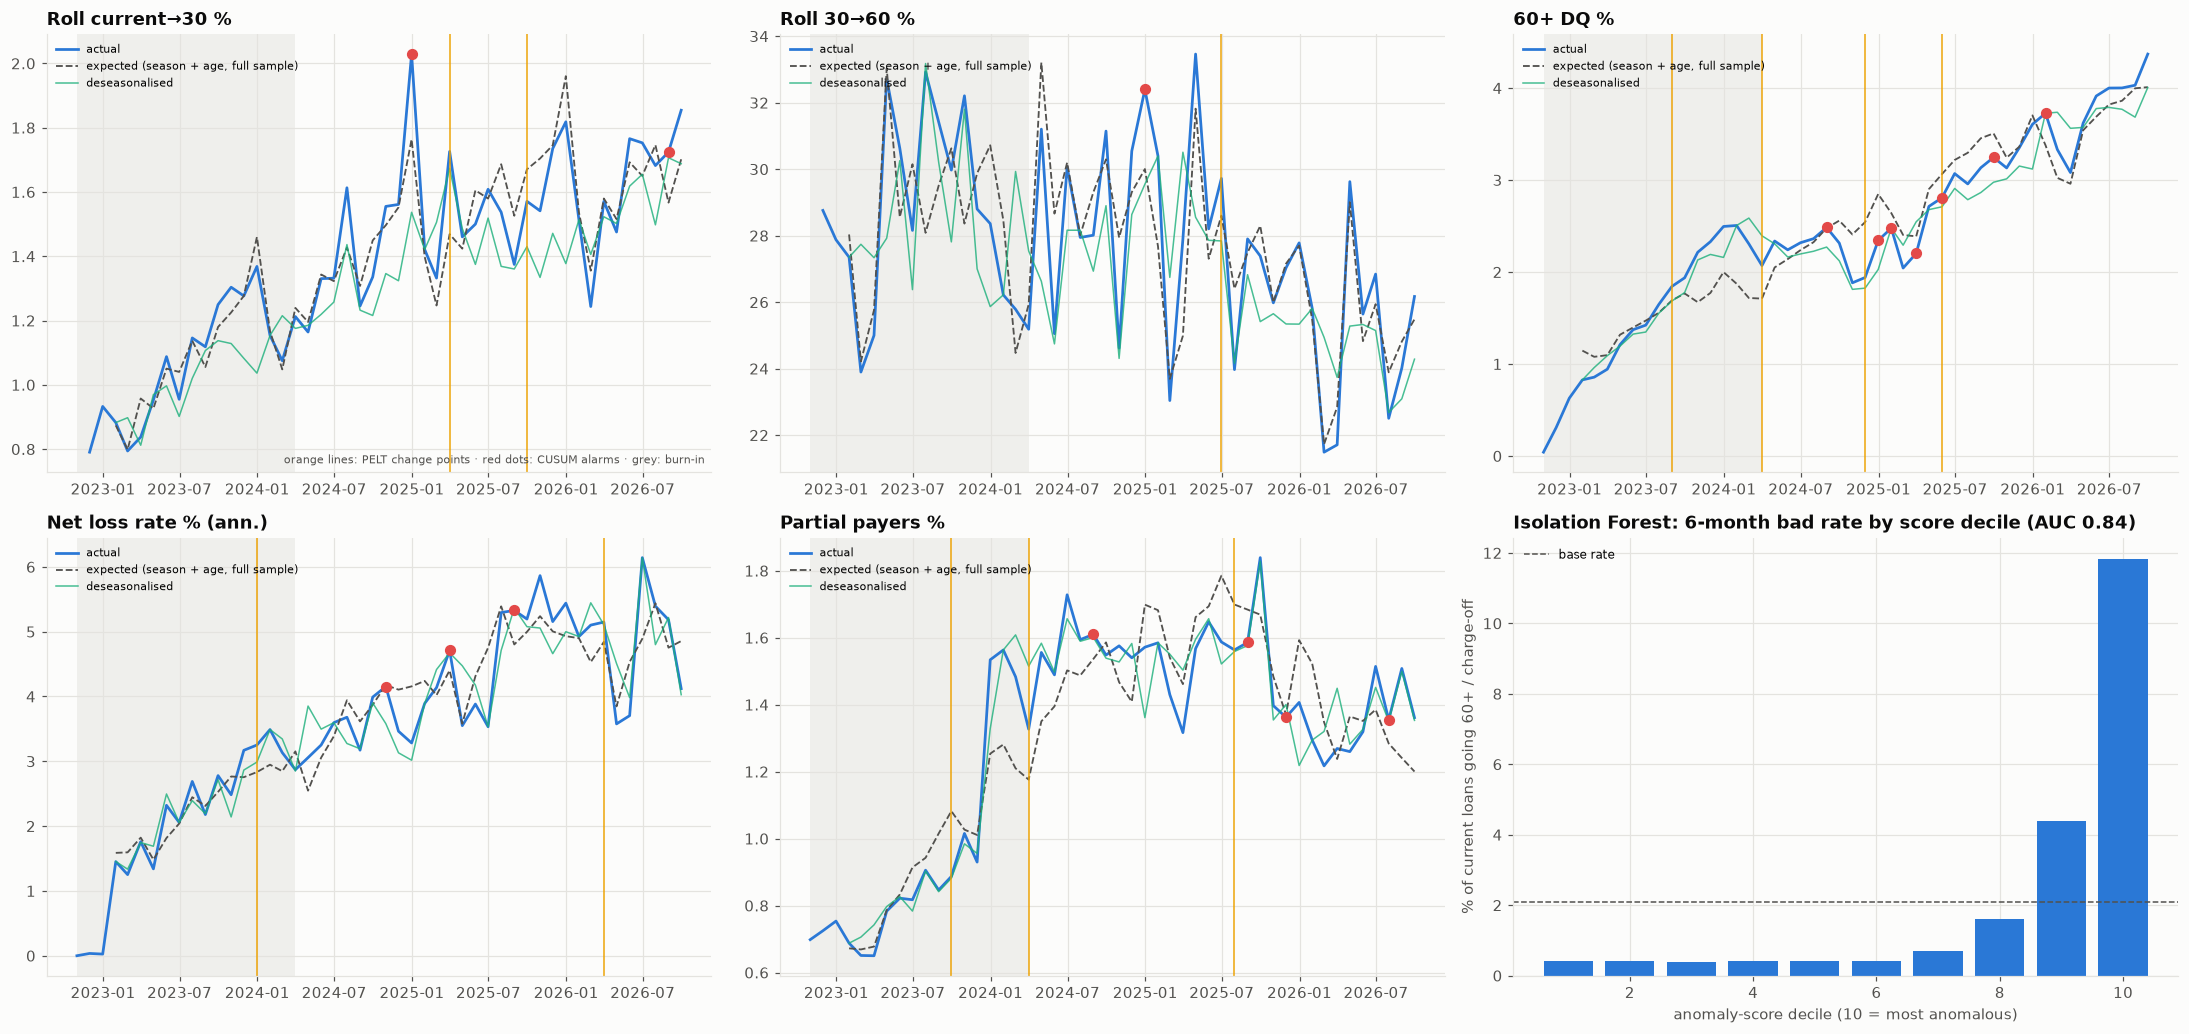

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(20, 9.5))
for ax, col in zip(axes.flat[:5], MON):
    s = ind[col]
    ax.plot(s.index, s, color=PALETTE[0], lw=1.8, label="actual")
    ax.plot(
        expected[col].index,
        expected[col],
        color=INK_2,
        ls="--",
        lw=1.2,
        label="expected (season + age, full sample)",
    )
    ax.plot(
        trend[col].index,
        trend[col],
        color=PALETTE[2],
        lw=1,
        alpha=0.8,
        label="deseasonalised",
    )
    for d_ in cps[col]:
        ax.axvline(d_, color=PALETTE[3], lw=1.2, alpha=0.8)
    for d_ in cusum[col][1]:
        ax.scatter([d_], [s.loc[d_]], color=STATUS["red"], zorder=5, s=40)
    ax.axvspan(
        s.index[0],
        s.loc[START:].dropna().index[BURN - 1],
        color=GRID,
        alpha=0.5,
        lw=0,
    )
    ax.set_title(MON[col])
    ax.legend(fontsize=7, loc="upper left")
axes[0, 0].text(
    0.99,
    0.02,
    "orange lines: PELT change points · red dots: CUSUM alarms · grey:"
    " burn-in",
    transform=axes[0, 0].transAxes,
    ha="right",
    fontsize=7,
    color=INK_2,
)
ax = axes[1, 2]
ax.bar(lift.index.astype(int), lift["bad rate"], color=PALETTE[0])
ax.axhline(
    te["bad_next"].mean() * 100, color=INK_2, ls="--", lw=1, label="base rate"
)
ax.set_title(
    "Isolation Forest: 6-month bad rate by score decile (AUC"
    f" {auc['Isolation Forest score (unsupervised)']:.2f})"
)
ax.set_xlabel("anomaly-score decile (10 = most anomalous)")
ax.set_ylabel("% of current loans going 60+ / charge-off")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_indicators_changepoints_anomalies")
plt.show()

## 9. Surveillance dashboard

RAG status for each monitored indicator:
- **red:** a CUSUM alarm in the last three months, or a latest standardised residual above 2;
- **amber:** a residual between 1 and 2;
- **green:** otherwise.

In [11]:
rag = []
for col, label in MON.items():
    e_, al = cusum[col]
    recent = any(a_ >= ind.index[-3] for a_ in al)
    r_ = e_["error"].iloc[-1]
    rag.append({
        "indicator": label,
        "latest": ind[col].iloc[-1],
        "expected": expected[col].iloc[-1],
        "residual (s.d.)": r_,
        "status": (
            "red" if recent or r_ > 2 else "amber" if r_ > 1 else "green"
        ),
    })
rag = pd.DataFrame(rag)
color_map = {
    "red": STATUS["red"],
    "amber": STATUS["amber"],
    "green": STATUS["green"],
}

dash = make_subplots(
    rows=3,
    cols=4,
    specs=[
        [{"type": "indicator"}] * 4,
        [
            {"type": "xy", "colspan": 2},
            None,
            {"type": "xy", "colspan": 2},
            None,
        ],
        [
            {"type": "table", "colspan": 2},
            None,
            {"type": "table", "colspan": 2},
            None,
        ],
    ],
    row_heights=[0.16, 0.44, 0.40],
    vertical_spacing=0.08,
    subplot_titles=(
        "",
        "",
        "",
        "",
        "60+ delinquency: actual vs expected",
        "Roll current→30 and CUSUM alarms",
        "Indicator status",
        "Segment control chart (latest month)",
    ),
)
L = ind.iloc[-1]
for i, (val, fmt, ttl) in enumerate([
    (L["pool factor %"], ".1f", "Pool factor %"),
    (L["dq60"], ".2f", "60+ DQ %"),
    (L["cnl"], ".2f", "Cumulative net loss %"),
    (L["nlr"], ".2f", "Net loss rate % (ann.)"),
]):
    dash.add_trace(
        go.Indicator(
            mode="number",
            value=val,
            number={"valueformat": fmt},
            title={
                "text": (
                    f"{ttl}<br><span"
                    f" style='font-size:11px'>{ind.index[-1]:%b %Y}</span>"
                )
            },
        ),
        1,
        i + 1,
    )
dash.add_trace(
    go.Scatter(
        x=ind.index,
        y=ind["dq60"],
        name="60+ DQ %",
        line=dict(color=PALETTE[0]),
    ),
    2,
    1,
)
dash.add_trace(
    go.Scatter(
        x=expected["dq60"].index,
        y=expected["dq60"],
        name="expected",
        line=dict(color=INK_2, dash="dash"),
    ),
    2,
    1,
)
dash.add_trace(
    go.Scatter(
        x=ind.index,
        y=ind["roll_c30"],
        name="roll C→30 %",
        line=dict(color=PALETTE[1]),
    ),
    2,
    3,
)
dash.add_trace(
    go.Scatter(
        x=expected["roll_c30"].index,
        y=expected["roll_c30"],
        name="expected",
        line=dict(color=INK_2, dash="dot"),
        showlegend=False,
    ),
    2,
    3,
)
al = cusum["roll_c30"][1]
dash.add_trace(
    go.Scatter(
        x=al,
        y=ind.loc[al, "roll_c30"],
        mode="markers",
        name="CUSUM alarm",
        marker=dict(color=STATUS["red"], size=10),
    ),
    2,
    3,
)
dash.add_trace(
    go.Table(
        header=dict(
            values=[
                "indicator",
                "latest",
                "expected",
                "residual (s.d.)",
                "status",
            ],
            fill_color=GRID,
        ),
        cells=dict(
            values=[
                rag["indicator"],
                rag["latest"].round(2),
                rag["expected"].round(2),
                rag["residual (s.d.)"].round(2),
                rag["status"],
            ],
            fill_color=[["white"] * len(rag)] * 4
            + [[color_map[s_] for s_ in rag["status"]]],
        ),
    ),
    3,
    1,
)
st = seg_tab.head(10)
dash.add_trace(
    go.Table(
        header=dict(
            values=[
                "segment",
                "loans",
                "60+ % latest",
                "60+ % prior 12m",
                "z",
            ],
            fill_color=GRID,
        ),
        cells=dict(
            values=[
                st.index,
                st["loans"],
                st["60+ % latest"].round(2),
                st["60+ % prior 12m"].round(2),
                st["z"].round(1),
            ],
            fill_color=[["white"] * len(st)] * 4
            + [[color_map[f_] for f_ in st["flag"]]],
        ),
    ),
    3,
    3,
)
dash.update_layout(
    height=1000,
    width=1500,
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    margin=dict(t=90, l=40, r=30, b=60),
    title=dict(
        x=0.01,
        text="<b>CarMax Auto Owner Trust 2022-4 · pool surveillance</b>",
    ),
    legend=dict(orientation="h", x=0.0, y=-0.03, yanchor="top"),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

**The pool.** CarMax Auto Owner Trust 2022-4 holds 67,700 used-car loans: $1.43bn at the first report, mean credit score 714, APR 8.6%, 66-month terms. After four years it has paid down to a **12% pool factor**, with **cumulative net losses of 5.5%** of the initial balance.

Its 60+ delinquency rose in three phases:
- **ramp-up:** from almost nothing to 2.5% by December 2023, as the loans seasoned;
- **plateau:** 2.0–2.5% through 2024;
- **re-acceleration:** to **4.4%** by September 2026 (30+: 10.2%).

Part of the late rise is mechanical. As good borrowers pay off (CPR rose from 11–14% to about 21% in 2026), the remaining balance is increasingly the weaker loans. Over the same period:
- the monthly roll from current to 30 days late doubled, from 0.8% to 1.85%;
- the 30→60 roll stayed at 25–33% with no clear trend, so deterioration came from more borrowers *entering* delinquency, not fewer curing;
- the payment ratio fell from 104–110% of scheduled payments in 2023 to 97–101% in 2025–26.

**Change points and alarms.**
- **PELT dates the trend breaks in 60+ delinquency** to 2023-08 and 2024-03 (end of the ramp, start of the plateau), then 2024-11 and 2025-05 (re-acceleration). The current→30 roll breaks upward in 2025-03 and 2025-09.
- **The real-time CUSUM first alarms on 60+ delinquency in August 2024.** It alarms on partial payers in August 2024, net losses in October 2024 and both roll rates in December 2024. These are months where the pool ran above the curve extrapolated from its own history.
- **In this deal the flow indicators did not lead.** Their alarms came at the same time as, or after, the 60+ alarm. The current→30 roll's surprises correlate best with the 60+ surprises one month later (0.60 vs 0.52 at the same month), a modest lead. Partial payments carry no lead information.
- **The honest conclusion:** at the pool level, monthly ABS-EE flows give at most a month of warning over the 60+ rate. Most of the value is in confirming a trend sooner and with a statistical threshold, rather than eyeballing a noisy line.

**Loan-level anomalies are where the early warning is.** Among loans that are still current, the unsupervised Isolation Forest ranks those that go 60+ or are charged off within six months with an **out-of-time AUC of 0.84**. That beats the origination credit score (0.80); a supervised logistic regression on the same features reaches 0.90.
- **The most anomalous 1%** of current loan-months go bad at **24%**, eleven times the 2.1% base rate. The top decile holds **56%** of all bad outcomes.
- **Behaviour, not origination, makes them anomalous.** In the top 1%, 46% skipped this month's payment, 68% carry a modification or extension flag, and their minimum payment ratio over three months is 0.29. They sit, on average, 8 days past due while still counted as "current".
- **For a servicer or a warehouse lender this is the actionable list**: borrowers who have not yet missed enough to show up in delinquency.

**Segments.** In the latest month, nothing is red.
- **Two segments are amber:** loans on vehicles six or more years old at origination (60+ at 3.1% vs 2.6% over the prior year, z = 2.6) and, unexpectedly, borrowers with payment-to-income below 8% (1.6% vs 1.3%).
- **The deterioration is broad.** Almost every segment's z-score is positive, which points to a pool-wide (macro or seasoning) effect rather than one pocket. With 18 segments tested, one amber flag is expected by chance alone.

**RAG status (September 2026).** Current→30 roll and partial payers are **red**: each had a CUSUM alarm in the last three months, and both residuals are about +1.7 s.d. 60+ delinquency is green (+0.8 s.d.), and the net loss rate is below its expected path (−1.8 s.d.).

**Limitations**
- **One deal, so age and calendar time are confounded.** The expected path cannot tell normal seasoning from macro deterioration. The standard fix is a **static-pool benchmark**: the same indicators at the same loan age for the issuer's earlier deals (CarMax files one every quarter). That is the natural next step, at about 6 minutes of download per deal.
- **CUSUM thresholds are textbook values.** With ($k$ = 0.5, $h$ = 4) and 30 months of monitoring, the false-alarm rate is not calibrated; a production system would set $h$ from the desired average run length.
- **Delinquency is by balance on a shrinking pool**, which inflates late-life ratios. Investors also watch it against the *initial* balance, and deal triggers are usually written that way.
- **The anomaly detector uses behavioural flags** (modification, days past due within 1–29) that a rules-based watch list would also catch. Its edge over a simple rule is in combining them, and it was not compared with such a rule.
- **ABS-EE reporting conventions vary by issuer** (how extensions are flagged, when charge-offs and recoveries post), so indicator levels are not comparable across issuers without mapping.

In [12]:
ind.to_csv(OUT_DIR / "pool_indicators_monthly.csv")
cp_tab.to_csv(OUT_DIR / "change_points_and_alarms.csv")
lift.to_csv(OUT_DIR / "anomaly_lift_by_decile.csv")
seg_tab.to_csv(OUT_DIR / "segment_control_chart.csv")
rag.to_csv(OUT_DIR / "rag_status.csv", index=False)
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_indicators_changepoints_anomalies.png, dashboard.html, dashboard.png, anomaly_lift_by_decile.csv, change_points_and_alarms.csv, pool_indicators_monthly.csv, rag_status.csv, segment_control_chart.csv


## References

### Finance and regulation

- Page, E. S. (1954). Continuous inspection schemes. *Biometrika, 41*(1–2), 100–115. https://doi.org/10.1093/biomet/41.1-2.100
- Adams, W., Einav, L., & Levin, J. (2009). Liquidity constraints and imperfect information in subprime lending. *American Economic Review, 99*(1), 49–84. https://doi.org/10.1257/aer.99.1.49

### Machine learning and deep learning

- Killick, R., Fearnhead, P., & Eckley, I. A. (2012). Optimal detection of changepoints with a linear computational cost. *Journal of the American Statistical Association, 107*(500), 1590–1598. https://doi.org/10.1080/01621459.2012.737745
- Truong, C., Oudre, L., & Vayatis, N. (2020). Selective review of offline change point detection methods. *Signal Processing, 167*, 107299. https://doi.org/10.1016/j.sigpro.2019.107299
- Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). Isolation forest. In *Proceedings of the 2008 Eighth IEEE International Conference on Data Mining* (pp. 413–422). https://doi.org/10.1109/ICDM.2008.17
- Raasveldt, M., & Mühleisen, H. (2019). DuckDB: An embeddable analytical database. In *Proceedings of the 2019 International Conference on Management of Data*. https://doi.org/10.1145/3299869.3320212